In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


In [4]:
df = pd.read_csv('/content/movies.csv')

print("Dataset loaded successfully")

Dataset loaded successfully


In [7]:
df.head()


,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000.0,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000.0,46998772.0,Warner Bros.,146.0
1,The Blue Lagoon,R,Adventure,1980,"July 2, 1980 (United States)",5.8,65000.0,Randal Kleiser,Henry De Vere Stacpoole,Brooke Shields,United States,4500000.0,58853106.0,Columbia Pictures,104.0
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,1980,"June 20, 1980 (United States)",8.7,1200000.0,Irvin Kershner,Leigh Brackett,Mark Hamill,United States,18000000.0,538375067.0,Lucasfilm,124.0
3,Airplane!,PG,Comedy,1980,"July 2, 1980 (United States)",7.7,221000.0,Jim Abrahams,Jim Abrahams,Robert Hays,United States,3500000.0,83453539.0,Paramount Pictures,88.0
4,Caddyshack,R,Comedy,1980,"July 25, 1980 (United States)",7.3,108000.0,Harold Ramis,Brian Doyle-Murray,Chevy Chase,United States,6000000.0,39846344.0,Orion Pictures,98.0


In [8]:
df.tail()

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
7663,More to Life,NaN,Drama,2020,"October 23, 2020 (United States)",3.1,18.0,Joseph Ebanks,Joseph Ebanks,Shannon Bond,United States,7000.0,NaN,NaN,90.0
7664,Dream Round,NaN,Comedy,2020,"February 7, 2020 (United States)",4.7,36.0,Dusty Dukatz,Lisa Huston,Michael Saquella,United States,NaN,NaN,Cactus Blue Entertainment,90.0
7665,Saving Mbango,NaN,Drama,2020,"April 27, 2020 (Cameroon)",5.7,29.0,Nkanya Nkwai,Lynno Lovert,Onyama Laura,United States,58750.0,NaN,Embi Productions,NaN
7666,It's Just Us,NaN,Drama,2020,"October 1, 2020 (United States)",NaN,NaN,James Randall,James Randall,Christina Roz,United States,15000.0,NaN,NaN,120.0
7667,Tee em el,NaN,Horror,2020,"August 19, 2020 (United States)",5.7,7.0,Pereko Mosia,Pereko Mosia,Siyabonga Mabaso,South Africa,NaN,NaN,PK 65 Films,102.0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7668 entries, 0 to 7667
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   name      7668 non-null   object 
 1   rating    7591 non-null   object 
 2   genre     7668 non-null   object 
 3   year      7668 non-null   int64  
 4   released  7666 non-null   object 
 5   score     7665 non-null   float64
 6   votes     7665 non-null   float64
 7   director  7668 non-null   object 
 8   writer    7665 non-null   object 
 9   star      7667 non-null   object 
 10  country   7665 non-null   object 
 11  budget    5497 non-null   float64
 12  gross     7479 non-null   float64
 13  company   7651 non-null   object 
 14  runtime   7664 non-null   float64
dtypes: float64(5), int64(1), object(9)
memory usage: 898.7+ KB


In [10]:
df.describe()

,year,score,votes,budget,gross,runtime
count,7668.000000,7665.000000,7.665000e+03,5.497000e+03,7.479000e+03,7664.000000
mean,2000.405451,6.390411,8.810850e+04,3.558988e+07,7.850054e+07,107.261613
std,11.153508,0.968842,1.633238e+05,4.145730e+07,1.657251e+08,18.581247
min,1980.000000,1.900000,7.000000e+00,3.000000e+03,3.090000e+02,55.000000
25%,1991.000000,5.800000,9.100000e+03,1.000000e+07,4.532056e+06,95.000000
50%,2000.000000,6.500000,3.300000e+04,2.050000e+07,2.020576e+07,104.000000
75%,2010.000000,7.100000,9.300000e+04,4.500000e+07,7.601669e+07,116.000000
max,2020.000000,9.300000,2.400000e+06,3.560000e+08,2.847246e+09,366.000000


In [11]:
df.isnull().sum()

,0
name,0
rating,77
genre,0
year,0
released,2
score,3
votes,3
director,0
writer,3
star,1


In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df = df.drop(
    columns=['released', 'writer', 'star'],
    errors='ignore'
)

print("Unnecessary columns removed")

Unnecessary columns removed


In [14]:
numeric_columns = [
    'year',
    'score',
    'votes',
    'budget',
    'gross',
    'runtime'
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(',', '', regex=False),
        errors='coerce'
    )

print(df.dtypes)

name         object
rating       object
genre        object
year          int64
score       float64
votes       float64
director     object
country      object
budget      float64
gross       float64
company      object
runtime     float64
dtype: object


In [15]:
df = df.drop_duplicates()

print("Duplicate records removed")

Duplicate records removed


In [18]:
df['profit'] = df['gross'] - df['budget']

In [19]:
df['decade'] = (df['year'] // 10) * 10

print(df[['name', 'year', 'profit', 'decade']].head())

                                             name  year       profit  decade
0                                     The Shining  1980   27998772.0    1980
1                                 The Blue Lagoon  1980   54353106.0    1980
2  Star Wars: Episode V - The Empire Strikes Back  1980  520375067.0    1980
3                                       Airplane!  1980   79953539.0    1980
4                                      Caddyshack  1980   33846344.0    1980


In [20]:
df.isnull().sum()

,0
name,0
rating,77
genre,0
year,0
score,3
votes,3
director,0
country,3
budget,2171
gross,189


In [21]:
print("Average IMDb Score:", df['score'].mean())

print("Average Votes:", df['votes'].mean())

print("Average Runtime:", df['runtime'].mean())

Average IMDb Score: 6.390410958904109
Average Votes: 88108.50476190477
Average Runtime: 107.2616127348643


In [23]:
df['score'] = df['score'].fillna(df['score'].mean())

df['votes'] = df['votes'].fillna(df['votes'].mean())

df['runtime'] = df['runtime'].fillna(df['runtime'].mean())

In [24]:
df['genre'] = df['genre'].fillna('Unknown')

df['director'] = df['director'].fillna('Unknown')

df['country'] = df['country'].fillna('Unknown')

df['company'] = df['company'].fillna('Unknown')

In [25]:
df.isnull().sum()

,0
name,0
rating,77
genre,0
year,0
score,0
votes,0
director,0
country,0
budget,2171
gross,189


In [26]:
top_movies = df.sort_values(
    by='score',
    ascending=False
)

print(top_movies[['name', 'score']].head(10))

                                                   name  score
2443                           The Shawshank Redemption    9.3
5243                                    The Dark Knight    9.0
4245      The Lord of the Rings: The Return of the King    8.9
2444                                       Pulp Fiction    8.9
2247                                   Schindler's List    8.9
3845  The Lord of the Rings: The Fellowship of the Ring    8.8
3444                                         Fight Club    8.8
2445                                       Forrest Gump    8.8
5643                                          Inception    8.8
3443                                         The Matrix    8.7


In [27]:
genre_count = df['genre'].value_counts()

print(genre_count.head(10))

genre
Comedy       2245
Action       1705
Drama        1518
Crime         551
Biography     443
Adventure     427
Animation     338
Horror        322
Fantasy        44
Mystery        20
Name: count, dtype: int64


In [28]:
genre_rating = df.groupby('genre')['score'].mean()

print(genre_rating.sort_values(ascending=False).head(10))

genre
History      8.300000
Musical      8.050000
Music        7.200000
Biography    7.030926
Animation    6.769231
Drama        6.693268
Crime        6.671506
Mystery      6.665000
Romance      6.410000
Family       6.363636
Name: score, dtype: float64


In [29]:
year_count = df.groupby('year')['name'].count()

print(year_count.sort_values(ascending=False).head(10))

year
1988    200
1986    200
1987    200
1985    200
1993    200
1992    200
1991    200
1990    200
1989    200
2005    200
Name: name, dtype: int64


In [30]:
top_revenue = df.sort_values(
    by='gross',
    ascending=False
)

print(top_revenue[['name', 'gross']].head(10))

                                            name         gross
5445                                      Avatar  2.847246e+09
7445                           Avengers: Endgame  2.797501e+09
3045                                     Titanic  2.201647e+09
6663  Star Wars: Episode VII - The Force Awakens  2.069522e+09
7244                      Avengers: Infinity War  2.048360e+09
7480                               The Lion King  1.670728e+09
6653                              Jurassic World  1.670516e+09
6043                                The Avengers  1.518816e+09
6646                                   Furious 7  1.515341e+09
7494                                   Frozen II  1.450027e+09


In [31]:
print("Average Runtime:", df['runtime'].mean(), "minutes")

Average Runtime: 107.2616127348643 minutes


In [32]:
decade_profit = df.groupby('decade')['profit'].mean()

print(decade_profit)

decade
1980    2.217195e+07
1990    3.669609e+07
2000    6.621141e+07
2010    1.212497e+08
2020    1.764252e+08
Name: profit, dtype: float64


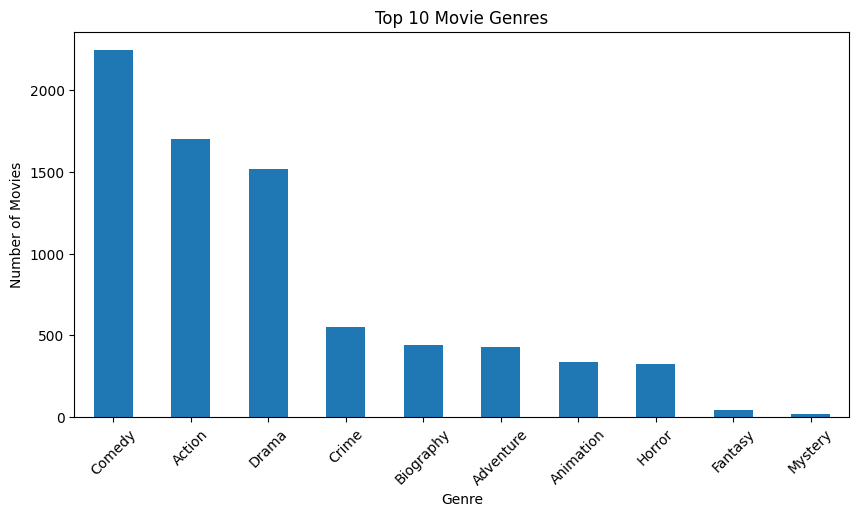

In [33]:
plt.figure(figsize=(10,5))

genre_count.head(10).plot(kind='bar')

plt.title('Top 10 Movie Genres')
plt.xlabel('Genre')
plt.ylabel('Number of Movies')
plt.xticks(rotation=45)

plt.show()

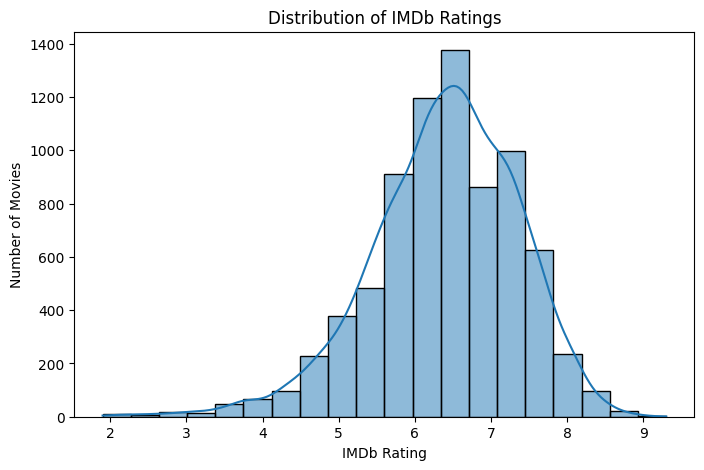

In [34]:
plt.figure(figsize=(8,5))

sns.histplot(df['score'], bins=20, kde=True)

plt.title('Distribution of IMDb Ratings')
plt.xlabel('IMDb Rating')
plt.ylabel('Number of Movies')

plt.show()

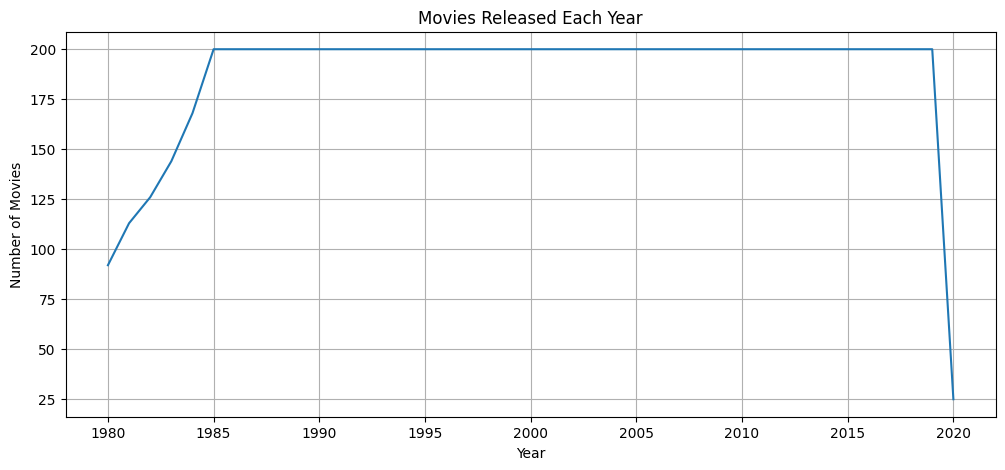

In [35]:
plt.figure(figsize=(12,5))

year_count.sort_index().plot(kind='line')

plt.title('Movies Released Each Year')
plt.xlabel('Year')
plt.ylabel('Number of Movies')

plt.grid()
plt.show()

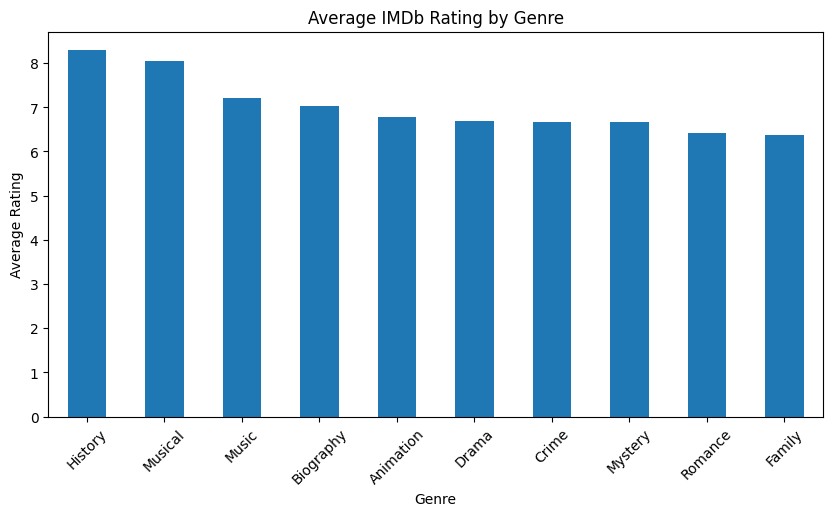

In [36]:
plt.figure(figsize=(10,5))

genre_rating.sort_values(ascending=False).head(10).plot(kind='bar')

plt.title('Average IMDb Rating by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Rating')
plt.xticks(rotation=45)

plt.show()

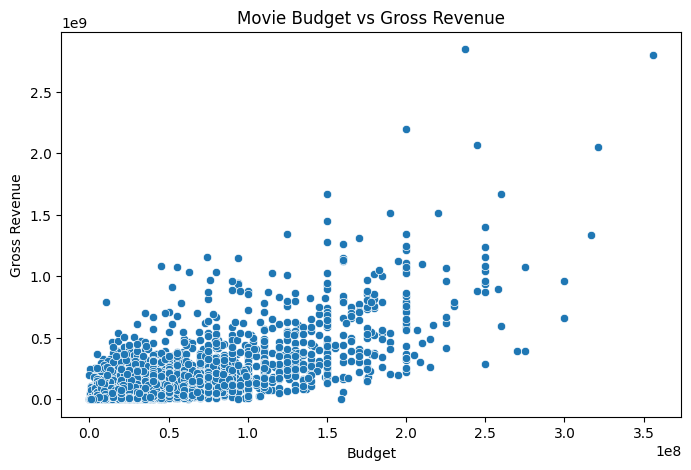

In [37]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='budget',
    y='gross'
)

plt.title('Movie Budget vs Gross Revenue')
plt.xlabel('Budget')
plt.ylabel('Gross Revenue')

plt.show()

In [5]:
df['score'] = pd.to_numeric(df['score'], errors='coerce')
df['year'] = pd.to_numeric(df['year'], errors='coerce')
df['gross'] = pd.to_numeric(df['gross'], errors='coerce')
df['runtime'] = pd.to_numeric(df['runtime'], errors='coerce')

common_genre = df['genre'].mode()[0]

highest_rated = df.loc[df['score'].idxmax(), 'name']

average_rating = df['score'].mean()

year_count = df['year'].value_counts()
highest_movie_year = int(year_count.idxmax())

highest_gross_movie = df.loc[df['gross'].idxmax(), 'name']

average_runtime = df['runtime'].mean()

genre_rating = df.groupby('genre')['score'].mean()
highest_rated_genre = genre_rating.idxmax()

print("PROJECT OBSERVATIONS")
print("----------------------------")

print("1. Most common movie genre:", common_genre)
print("2. Highest-rated movie:", highest_rated)
print("3. Average IMDb rating:", round(average_rating, 2))
print("4. Year with highest number of movies:", highest_movie_year)
print("5. Movie with highest gross revenue:", highest_gross_movie)
print("6. Average movie runtime:", round(average_runtime, 2), "minutes")
print("7. Genre with highest average rating:", highest_rated_genre)

PROJECT OBSERVATIONS
----------------------------
1. Most common movie genre: Comedy
2. Highest-rated movie: The Shawshank Redemption
3. Average IMDb rating: 6.39
4. Year with highest number of movies: 1988
5. Movie with highest gross revenue: Avatar
6. Average movie runtime: 107.26 minutes
7. Genre with highest average rating: History


In [6]:
df.to_csv('imdb_cleaned.csv', index=False)

print("Cleaned dataset saved successfully")

Cleaned dataset saved successfully


In [7]:
from google.colab import files

files.download('imdb_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>